# Домашнее задание "Корреляционный и регрессионный анализ"

Инструкции:
- Скачайте файл `practical_module_dataset.csv` и заполните ячейки с заданиями кодом и выводами.
- В каждой задаче требуется: короткая формулировка метода, код и расчёты, численные результаты (коэффициенты, статистики, p-value, CI, R^2) и краткий вывод (1-2 фразы).
- Разрешённые библиотеки: `numpy`, `pandas`, `scipy`, `statsmodels`, `scikit-learn`, `matplotlib`.
- Для воспроизводимости задан `np.random.seed` - не меняйте его.

Формат сдачи: .ipynb с заполненными ячейками, кодом и выводами.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from scipy import stats
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.outliers_influence import variance_inflation_factor

np.random.seed(28)

In [2]:
CSV_NAME = "practical_module_dataset.csv"
CSV_URL = (
    "https://raw.githubusercontent.com/radif-ru/applied-statistics/main/data/"
    + CSV_NAME
)
# файл рядом с ноутбуком (как в задании), в data/ репозитория или — в Colab — по ссылке
local = next(
    (p for p in (Path(CSV_NAME), Path("../data") / CSV_NAME) if p.exists()), None
)
df = pd.read_csv(local or CSV_URL)
print(df.shape)
df.head()

(30, 8)


,id,age,height_cm,weight_kg,iq,tv_hours,study_hours,score
0,1,24,155.2,51.37,91,11,11.9,76.5
1,2,37,184.9,76.49,90,15,4.0,65.4
2,3,32,169.8,64.24,98,6,10.6,78.2
3,4,28,173.6,68.22,88,9,9.2,75.6
4,5,25,174.2,73.80,102,8,8.0,75.1


### Задание 1. Первичный анализ данных (EDA)

- Посмотрите на основные статистические показатели для **всех** переменных.
- Проверьте типы данных и наличие пропусков.
- Постройте гистограммы числовых признаков.
- Запишите наблюдения в текстовой ячейке.

Типы столбцов: {'id': 'int64', 'age': 'int64', 'height_cm': 'float64', 'weight_kg': 'float64', 'iq': 'int64', 'tv_hours': 'int64', 'study_hours': 'float64', 'score': 'float64'}
Пропуски: {'id': 0, 'age': 0, 'height_cm': 0, 'weight_kg': 0, 'iq': 0, 'tv_hours': 0, 'study_hours': 0, 'score': 0}
Повторы id: 0


,count,mean,std,min,25%,50%,75%,max,skew,outliers_iqr
id,30.0,15.50,8.80,1.00,8.25,15.50,22.75,30.00,0.00,0
age,30.0,29.40,6.67,18.00,24.25,29.00,35.50,39.00,-0.09,0
height_cm,30.0,169.15,9.58,148.20,163.25,169.75,174.10,185.80,-0.27,0
weight_kg,30.0,62.73,9.20,44.75,56.62,63.68,68.60,81.13,-0.09,0
iq,30.0,100.43,12.12,82.00,91.00,97.00,109.75,132.00,0.88,0
tv_hours,30.0,12.27,3.83,6.00,9.00,12.00,14.00,22.00,0.88,2
study_hours,30.0,7.64,3.28,2.70,4.98,7.65,9.45,14.40,0.21,0
score,30.0,73.40,8.25,58.90,67.80,74.30,78.73,91.50,0.14,0


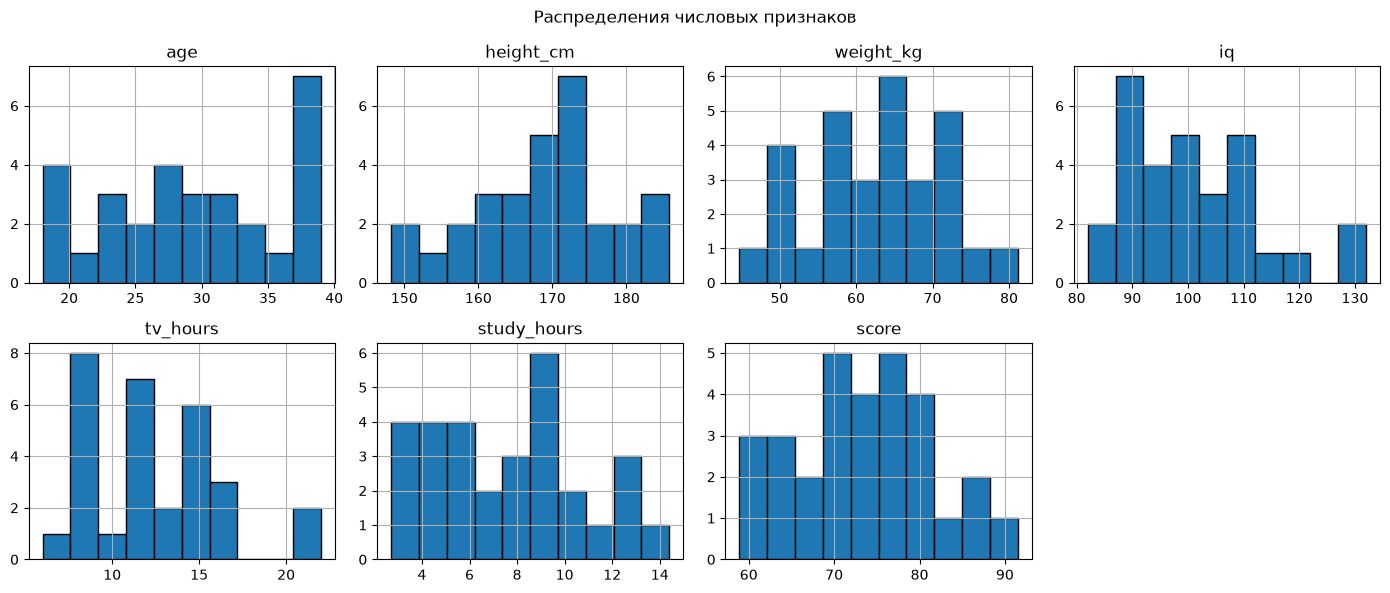

In [3]:
print("Типы столбцов:", df.dtypes.astype(str).to_dict())
print("Пропуски:", df.isna().sum().to_dict())
print("Повторы id:", df["id"].duplicated().sum())

features = df.columns.drop("id")  # id — номер записи, а не признак
q1, q3 = df.quantile(0.25), df.quantile(0.75)
iqr = q3 - q1
outside = (df < q1 - 1.5 * iqr) | (df > q3 + 1.5 * iqr)

summary = df.describe().T
summary["skew"] = df.skew()
summary["outliers_iqr"] = outside.sum()
display(summary.round(2))

df[features].hist(bins=10, figsize=(14, 6), layout=(2, 4), edgecolor="black")
plt.suptitle("Распределения числовых признаков")
plt.tight_layout()
plt.show()

**Вывод:** 30 наблюдений, 8 числовых столбцов (int64/float64), пропусков и повторов id нет. Рост, вес, возраст, score и study_hours распределены почти симметрично (|skew| $\le 0.27$); у iq и tv_hours заметная правая асимметрия (skew $\approx 0.88$) — правый хвост из нескольких больших значений (iq до 132, tv_hours до 22). По правилу 1.5·IQR выбросы есть только у tv_hours (2 значения по 22 ч), в остальных признаках их нет.

### Задание 2. Связь height_cm и weight_kg

- Постройте scatter plot по признакам `height_cm` и `weight_kg`.
- Посчитайте коэффициент Пирсона и p-value.
- Интерпретируйте силу, направление и значимость связи в выводе.

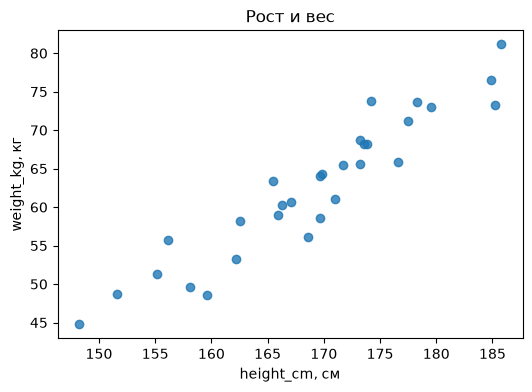

Пирсон: r = 0.9435, p-value = 5.80e-15


In [4]:
r, p_value = stats.pearsonr(df["height_cm"], df["weight_kg"])

fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(df["height_cm"], df["weight_kg"], alpha=0.8)
ax.set(title="Рост и вес", xlabel="height_cm, см", ylabel="weight_kg, кг")
plt.show()

print(f"Пирсон: r = {r:.4f}, p-value = {p_value:.2e}")

**Вывод:** $r \approx 0.944$, p-value $\approx 5.8 \cdot 10^{-15}$ — сильная положительная линейная связь: чем выше человек, тем больше вес; на диаграмме рассеяния точки плотно лежат вдоль возрастающей прямой. Связь статистически значима: при $H_0: \rho = 0$ такой коэффициент практически невозможен.

### Задание 3. Связь tv_hours и iq

- Посчитайте ранговый коэффициент Спирмена между `tv_hours` и `iq` и p-value.
- Оцените, есть ли монотонная связь в выводе.

In [5]:
rho, p_value = stats.spearmanr(df["tv_hours"], df["iq"])
print(f"Спирмен: r_s = {rho:.4f}, p-value = {p_value:.4f}")

Спирмен: r_s = -0.2108, p-value = 0.2635


**Вывод:** $r_s \approx -0.21$, p-value $\approx 0.26 > 0.05$ — слабая отрицательная тенденция, но статистически незначимая: монотонной связи между временем у телевизора и IQ на этих данных не обнаружено.

### Задание 4. Простая линейная регрессия weight_kg ~ height_cm

- Постройте регрессию, найдите intercept и slope, 95% доверительный интервал для наклона.
- Интерпретируйте результат в выводе.

In [6]:
model_simple = sm.OLS(df["weight_kg"], sm.add_constant(df["height_cm"])).fit()
intercept, slope = model_simple.params
slope_low, slope_high = model_simple.conf_int(alpha=0.05).loc["height_cm"]

print(f"intercept = {intercept:.4f}")
print(f"slope = {slope:.4f} (p-value = {model_simple.pvalues['height_cm']:.2e})")
print(f"95% доверительный интервал для наклона: [{slope_low:.4f}; {slope_high:.4f}]")
print(f"R^2 = {model_simple.rsquared:.4f}")

intercept = -90.4962
slope = 0.9059 (p-value = 5.80e-15)
95% доверительный интервал для наклона: [0.7827; 1.0290]
R^2 = 0.8903


**Вывод:** $\widehat{\text{weight}} = -90.50 + 0.906 \cdot \text{height}$. Каждый дополнительный сантиметр роста в среднем добавляет 0.91 кг веса; с вероятностью 95% истинный наклон лежит в $[0.78;\ 1.03]$ кг/см — интервал далеко от нуля, связь значима. Свободный член не интерпретируется буквально (рост 0 см вне данных) и лишь задаёт положение прямой; модель объясняет $R^2 \approx 89\%$ вариации веса.

### Задание 5. Прогноз и предсказательный интервал

- Для `height_cm = 175` вычислите точечный прогноз веса и 95% предсказательный интервал для нового наблюдения.

In [7]:
new_x = pd.DataFrame({"const": [1.0], "height_cm": [175.0]})
pred = model_simple.get_prediction(new_x).summary_frame(alpha=0.05).iloc[0]

print(f"Точечный прогноз веса при росте 175 см: {pred['mean']:.2f} кг")
print(
    f"95% доверительный интервал для среднего веса: "
    f"[{pred['mean_ci_lower']:.2f}; {pred['mean_ci_upper']:.2f}] кг"
)
print(
    f"95% предсказательный интервал для нового наблюдения: "
    f"[{pred['obs_ci_lower']:.2f}; {pred['obs_ci_upper']:.2f}] кг"
)

Точечный прогноз веса при росте 175 см: 68.03 кг
95% доверительный интервал для среднего веса: [66.66; 69.40] кг
95% предсказательный интервал для нового наблюдения: [61.53; 74.53] кг


**Вывод:** при росте 175 см ожидаемый вес — 68.03 кг. Средний вес всех людей такого роста оценён точно ($[66.66;\ 69.40]$ кг), но для одного нового человека 95% предсказательный интервал заметно шире — $[61.53;\ 74.53]$ кг, потому что к неопределённости оценки прямой добавляется индивидуальный разброс вокруг неё.

### Задание 6. Множественная регрессия

- Постройте модель score `~ study_hours + iq + tv_hours + age`.
- Выведите R^2 и оцените значимость предикторов по p-value.
- Дополнительно проверьте мультиколлинеарность через VIF.
- Запшите наблюдения в выводе.

In [8]:
predictors = ["study_hours", "iq", "tv_hours", "age"]
X_multi = sm.add_constant(df[predictors])
model_multi = sm.OLS(df["score"], X_multi).fit()

ci = model_multi.conf_int(alpha=0.05)
coefs = pd.DataFrame(
    {
        "coef": model_multi.params,
        "std_err": model_multi.bse,
        "t": model_multi.tvalues,
        "p_value": model_multi.pvalues,
        "ci_low": ci[0],
        "ci_high": ci[1],
    }
)
display(coefs.round(4))
print(f"R^2 = {model_multi.rsquared:.4f}")
print(f"Скорректированный R^2 = {model_multi.rsquared_adj:.4f}")
print(f"F-статистика = {model_multi.fvalue:.2f}, p-value = {model_multi.f_pvalue:.2e}")

vif = pd.Series(
    [
        variance_inflation_factor(X_multi.to_numpy(), i)
        for i in range(1, X_multi.shape[1])
    ],
    index=predictors,
    name="VIF",
)
display(vif.round(3).to_frame())

,coef,std_err,t,p_value,ci_low,ci_high
const,45.6584,6.8070,6.7076,0.0000,31.6391,59.6777
study_hours,2.0978,0.1934,10.8476,0.0000,1.6995,2.4961
iq,0.1479,0.0531,2.7849,0.0101,0.0385,0.2573
tv_hours,-0.1447,0.1586,-0.9126,0.3702,-0.4713,0.1819
age,-0.0465,0.0911,-0.5106,0.6141,-0.2342,0.1412


R^2 = 0.8741
Скорректированный R^2 = 0.8539
F-статистика = 43.38, p-value = 6.73e-11


,VIF
study_hours,1.174
iq,1.208
tv_hours,1.076
age,1.078


**Вывод:** модель объясняет $R^2 \approx 0.874$ вариации score (скорректированный $R^2 \approx 0.854$), F-тест модели значим (p $\approx 6.7 \cdot 10^{-11}$). Значимы study_hours (+2.10 балла за час занятий, p < 0.001) и iq (+0.15 балла за пункт, p $\approx 0.01$); tv_hours (p $\approx 0.37$) и age (p $\approx 0.61$) незначимы — их доверительные интервалы содержат ноль. Все VIF $\approx 1.1$–$1.2$ (далеко от порогов 5–10), мультиколлинеарности нет, оценки коэффициентов устойчивы.

### Задание 7. Ошибка модели

- Оцените типичную ошибку предсказаний модели из задания 6: вычислите RMSE (корень из средней квадратичной ошибки) на всей выборке и сравните её с разбросом целевой переменной (стандартным отклонением score).
- Насколько модель уменьшает типичную ошибку?

In [9]:
rmse = np.sqrt(np.mean(model_multi.resid**2))
# std с ddof=0 — это RMSE «модели», которая всегда предсказывает среднее score
score_std = df["score"].std(ddof=0)

print(f"RMSE модели = {rmse:.4f}")
print(f"Стандартное отклонение score = {score_std:.4f}")
print(
    f"RMSE / std = {rmse / score_std:.4f}, ошибка меньше на {1 - rmse / score_std:.1%}"
)

RMSE модели = 2.8797
Стандартное отклонение score = 8.1150
RMSE / std = 0.3549, ошибка меньше на 64.5%


**Вывод:** RMSE модели $\approx 2.88$ балла против стандартного отклонения score $\approx 8.11$ — типичная ошибка, если предсказывать всем среднее значение. Модель уменьшает типичную ошибку почти втрое (на 64.5%); отношение $0.355 = \sqrt{1 - R^2}$ согласуется с $R^2$ из задания 6.

### Задание 8. Градиентный спуск

- Реализуйте градиентный спуск для простой регрессии score `~ study_hours` и сравните коэффициенты со `statsmodels`.
- Ответьте на вопрос: возможно ли получить метрику алгоритмом градиентного спуска лучше, чем у МНК?

learning_rate = 0.01, n_iter = 10000


,gradient_descent,ols
intercept,56.034028,56.034028
slope,2.273033,2.273033
MSE,12.068919,12.068919


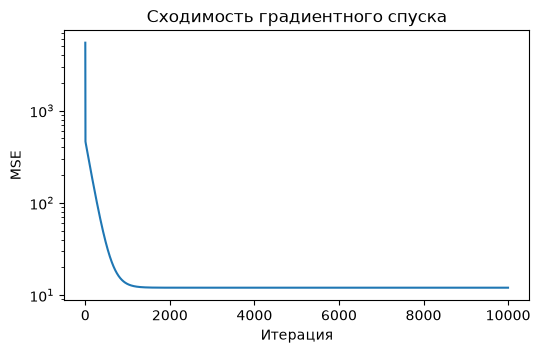

In [10]:
x = df["study_hours"].to_numpy()
y = df["score"].to_numpy()

# минимизируем MSE(b0, b1) = mean((b0 + b1 * x - y)^2)
learning_rate, n_iter = 0.01, 10_000
b0, b1 = 0.0, 0.0
mse_history = []
for _ in range(n_iter):
    error = b0 + b1 * x - y
    b0 -= learning_rate * 2 * error.mean()
    b1 -= learning_rate * 2 * (error * x).mean()
    mse_history.append(np.mean(error**2))

ols = sm.OLS(y, sm.add_constant(x)).fit()
comparison = pd.DataFrame(
    {
        "gradient_descent": [b0, b1, np.mean((b0 + b1 * x - y) ** 2)],
        "ols": [*ols.params, np.mean(ols.resid**2)],
    },
    index=["intercept", "slope", "MSE"],
)
print(f"learning_rate = {learning_rate}, n_iter = {n_iter}")
display(comparison.round(6))

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(mse_history)
ax.set(
    title="Сходимость градиентного спуска",
    xlabel="Итерация",
    ylabel="MSE",
    yscale="log",
)
plt.show()

**Вывод:** градиентный спуск (старт из нуля, learning_rate = 0.01, 10 000 итераций) сошёлся к решению МНК: intercept $\approx 56.034$, slope $\approx 2.273$, MSE $\approx 12.069$ совпадают с statsmodels до 6 знаков. Шаг ограничен кривизной MSE: при learning_rate выше $\approx 0.0144$ ($2/\lambda_{\max}$ гессиана) спуск расходится, при меньшем — сходится медленнее.

Получить метрику лучше, чем у МНК, градиентным спуском **нельзя**: МНК даёт точный и единственный минимум выпуклой функции MSE на обучающей выборке, поэтому спуск может к нему лишь приблизиться. Преимущество градиентного спуска — не в точности, а в масштабируемости (большие данные, мини-батчи, модели без аналитического решения).

### Задание 9. Бутстрэп-интервал для корреляции

- Постройте бутстрэп-оценку 95% доверительного интервала для коэффициента Пирсона между `height_cm` и `weight_kg` (1000 бутстрэп-итераций, перцентильный метод).

In [11]:
n_boot = 1000
height = df["height_cm"].to_numpy()
weight = df["weight_kg"].to_numpy()

boot_r = np.empty(n_boot)
for i in range(n_boot):
    idx = np.random.randint(0, len(df), len(df))  # выборка пар с возвращением
    boot_r[i] = np.corrcoef(height[idx], weight[idx])[0, 1]
ci_low, ci_high = np.percentile(boot_r, [2.5, 97.5])

print(f"Пирсон по выборке: r = {np.corrcoef(height, weight)[0, 1]:.4f}")
print(f"Бутстрэп-репликаций: {n_boot}")
print(f"95% перцентильный бутстрэп-интервал: [{ci_low:.4f}; {ci_high:.4f}]")

Пирсон по выборке: r = 0.9435
Бутстрэп-репликаций: 1000
95% перцентильный бутстрэп-интервал: [0.9021; 0.9705]


**Вывод:** по 1000 бутстрэп-репликациям (пары наблюдений выбираются с возвращением) 95% перцентильный интервал для $r$ — $[0.902;\ 0.971]$. Он несимметричен относительно $r \approx 0.944$ (сжат к 1, так как $r \le 1$) и целиком лежит в области сильной положительной связи, что подтверждает вывод задания 2.

### Задание 10. Диагностика остатков

Для модели из задания 6 проведите диагностику остатков:
- постройте график остатков против предсказанных значений,
- QQ-plot остатков и гистограмму остатков.

Сделайте вывод о выполнении предпосылок регрессии.

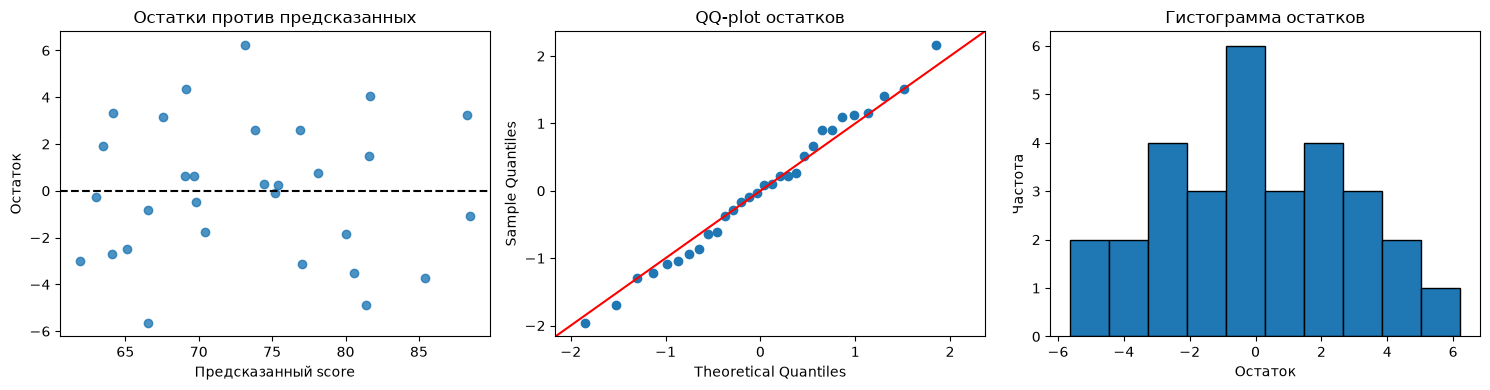

Шапиро-Уилк для остатков: p-value = 0.9616
Бройш-Пэган (гетероскедастичность): p-value = 0.9886


In [12]:
fitted, resid = model_multi.fittedvalues, model_multi.resid

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].scatter(fitted, resid, alpha=0.8)
axes[0].axhline(0, color="black", linestyle="--")
axes[0].set(
    title="Остатки против предсказанных", xlabel="Предсказанный score", ylabel="Остаток"
)
sm.qqplot(resid, line="45", fit=True, ax=axes[1])
axes[1].set_title("QQ-plot остатков")
axes[2].hist(resid, bins=10, edgecolor="black")
axes[2].set(title="Гистограмма остатков", xlabel="Остаток", ylabel="Частота")
plt.tight_layout()
plt.show()

print(f"Шапиро-Уилк для остатков: p-value = {stats.shapiro(resid).pvalue:.4f}")
bp_p_value = het_breuschpagan(resid, X_multi)[1]
print(f"Бройш-Пэган (гетероскедастичность): p-value = {bp_p_value:.4f}")

**Вывод:** остатки разбросаны вокруг нуля без тренда и «воронки» — линейная форма модели адекватна, дисперсия постоянна (Бройш-Пэган p $\approx 0.99$). Точки QQ-plot лежат на прямой, гистограмма близка к нормальной, Шапиро-Уилк p $\approx 0.96$ — нормальность ошибок не отвергается. Предпосылки линейной регрессии выполнены, поэтому p-value и доверительные интервалы задания 6 корректны.